Using an already trained model then specilizing it to a certain task
   Using ResNet-18

In [1]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.models import resnet18, ResNet18_Weights

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

weights = ResNet18_Weights.DEFAULT
transform = weights.transforms()

In [2]:
#Airplane, automobile, bird, cat, deer, dog, frog, horse, ship, and truck 
#has 3 color channels and 244 x 244 pixels each picture
train_dataset = datasets.CIFAR10(
    root="../data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.CIFAR10(
    root="../data",
    train=False,
    download=True,
    transform=transform
)

In [3]:
print("Training samples:", len(train_dataset))
print("Test samples:", len(test_dataset))
image, label = train_dataset[0]

print("Image shape:", image.shape)
print("Label:", label)

Training samples: 50000
Test samples: 10000
Image shape: torch.Size([3, 224, 224])
Label: 6


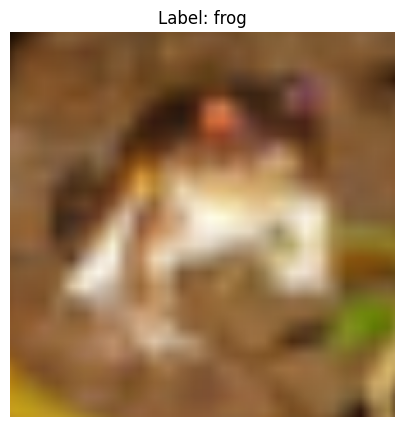

In [4]:
# Reverse ImageNet normalization for visualization
img = image.cpu().clone()

mean = torch.tensor(weights.transforms().mean).view(3, 1, 1)
std = torch.tensor(weights.transforms().std).view(3, 1, 1)

img = (img * std + mean).clamp(0, 1)

# Display the image
plt.figure(figsize=(5, 5))
plt.imshow(img.permute(1, 2, 0))
plt.title(f"Label: {train_dataset.classes[label]}")
plt.axis("off")
plt.show()

In [5]:
# download a already trained model
model = resnet18(weights=weights).to(device)

In [6]:
print(model.fc)

Linear(in_features=512, out_features=1000, bias=True)


In [7]:
# change model to only have 10 outputs instead of 1000
model.fc = nn.Linear( # makes the last layer different
    model.fc.in_features,# equal to 512
    len(train_dataset.classes) # equal to 10
).to(device) # equivelent to model.fc = nn.Linear(512, 10).to(device)

print(model.fc)

Linear(in_features=512, out_features=10, bias=True)


In [8]:
#Freeze all but the last layer since they are already useful and trained

for param in model.parameters():
    param.requires_grad = False

for param in model.fc.parameters():
    param.requires_grad = True

In [9]:
#make batches
from torch.utils.data import DataLoader

train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)

In [10]:
loss_fn = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.fc.parameters(), # fc is for final layer so it only changes the last layer
    lr=0.001
)

In [11]:
train_losses = []

for epoch in range(5):
    model.eval()  # it makes it stay consistant
    epoch_loss = []

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        output = model(images)
        loss = loss_fn(output, labels)

        loss.backward()
        optimizer.step()

        epoch_loss.append(loss.item())

    average_loss = sum(epoch_loss) / len(epoch_loss)
    train_losses.append(average_loss)

    print(f"Epoch {epoch + 1} -- Average Loss: {average_loss:.4f}")

Epoch 1 -- Average Loss: 0.6148
Epoch 2 -- Average Loss: 0.4204
Epoch 3 -- Average Loss: 0.3941
Epoch 4 -- Average Loss: 0.3820
Epoch 5 -- Average Loss: 0.3710


In [12]:
print("Classifier weights require gradients:",
      model.fc.weight.requires_grad)

print("Trainable parameters:",
      sum(p.numel() for p in model.parameters() if p.requires_grad))

print("Parameters tracked by optimizer:",
      sum(p.numel()
          for group in optimizer.param_groups
          for p in group["params"]))

print("Optimizer uses current classifier:",
      optimizer.param_groups[0]["params"][0] is model.fc.weight)

Classifier weights require gradients: True
Trainable parameters: 5130
Parameters tracked by optimizer: 5130
Optimizer uses current classifier: True
